# Control de dos grados de libertad (2-GDL): ángulo de cabeceo de un avión

En este notebook se diseña un controlador de **dos grados de libertad** para el ángulo de cabeceo $\theta$ de un avión, usando el método lineal algebraico de la función `cont2dof` de `DCMotor`. La respuesta de lazo cerrado deseada se obtiene con la función `itaemodel`.

Se analizan:

1. la respuesta al escalón del ángulo de cabeceo $\theta(t)$ y sus especificaciones;
2. la **señal de control** $u(t)$, que en este caso es el ángulo de deflexión del elevador $\delta_e$.

> Este notebook es solo de simulación: no requiere la plataforma DCMotor conectada.

In [ ]:
using DCMotor
using Plots

  Activating project at `~/datos/share_desktop/proyecto_julia/DCMotor.jl`


## 1. Modelo de la planta

La función de transferencia del ángulo del elevador $\delta_e$ (rad) al ángulo de cabeceo $\theta$ (rad) es

$$G(s) = \frac{\Theta(s)}{\Delta_e(s)} = \frac{1.151\,s + 0.1774}{s^3 + 0.739\,s^2 + 0.921\,s}.$$

Es una planta de orden $n = 3$ con un integrador ($s = 0$), un par de polos complejos en $-0.37 \pm 0.89j$ y un cero de fase mínima en $s \approx -0.154$.

In [3]:
s = tf("s")
G = (1.151s + 0.1774)/(s^3 + 0.739s^2 + 0.921s)   # 

TransferFunction{Continuous, ControlSystemsBase.SisoRational{Float64}}
     1.151s + 0.1774
--------------------------
1.0s^3 + 0.739s^2 + 0.921s

Continuous-time transfer function model

## 2. Respuesta deseada de lazo cerrado

Con `itaemodel(3, ω₀; type=:pos)` se obtiene un modelo ITAE de tercer orden con error de posición cero:

$$T(s) = \frac{\omega_0^3}{s^3 + 1.75\,\omega_0\, s^2 + 2.15\,\omega_0^2\, s + \omega_0^3}.$$

El parámetro $\omega_0$ fija la velocidad de la respuesta: un valor mayor da una respuesta más rápida, a costa de una señal de control mayor. 

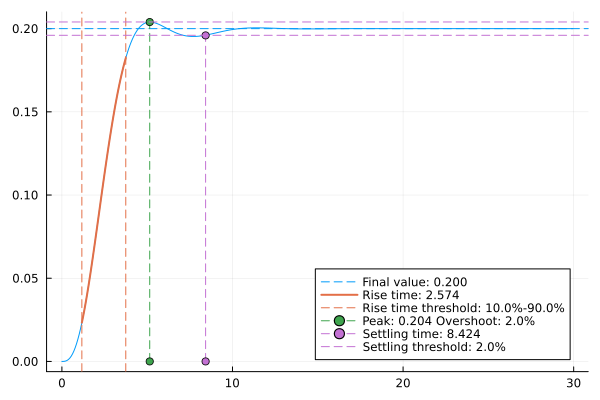

In [23]:
ω₀ = 0.9
reference = 0.2
T = itaemodel(3, ω₀; type=:pos)  
resultado =step(T*reference,30) # respuesta deseada de r a θ
plot(stepinfo(resultado))

## señal de control

Solo se puede usar una señal de control (angulo del alerón de cola) con

$|\delta_e(t)| \leq 30^o \approx 0.5 rad$


StepInfo:
Initial value:     0.000
Final value:       0.011
Step size:         0.011
Peak:              0.480
Peak time:         2.418 s
Overshoot:       4462.55 %
Undershoot:         0.00 %
Settling time:    29.874 s
Rise time:         0.000 s


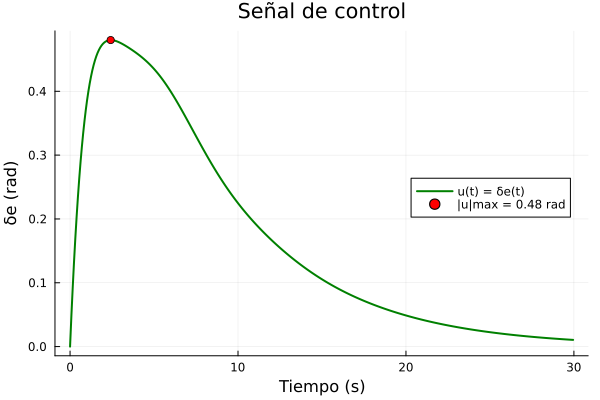

In [38]:
Gur = T/G
res_u = step(Gur, 30)

u = vec(res_u.y)
umax, imax = findmax(abs.(u))
print(stepinfo(ut))
plot(res_u.t, u, label="u(t) = δe(t)", xlabel="Tiempo (s)", ylabel="δe (rad)",
     title="Señal de control", color=:green, linewidth=2, legend=:right)
scatter!([res_u.t[imax]], [u[imax]], color=:red, label="|u|max = $(round(umax, digits=3)) rad")


## 3. Diseño del controlador de 2-GDL

El controlador de dos grados de libertad tiene la estructura

$$u = \frac{L(s)}{A(s)}\, r - \frac{M(s)}{A(s)}\, y,$$

de modo que el prefiltro $L/A$ (referencia) y la realimentación $M/A$ (salida) se diseñan por separado. La función `cont2dof(G, T, m, polos_obs)` calcula $L$, $A$ y $M$ para que la función de transferencia de $r$ a $y$ sea exactamente $T(s)$, y retorna

$$C(s) = \begin{bmatrix} \dfrac{L(s)}{A(s)} & -\dfrac{M(s)}{A(s)} \end{bmatrix}.$$

- El orden del controlador debe ser $m \ge n-1$; aquí se usa el mínimo, $m = 2$. Como la planta ya tiene un integrador, no se necesita acción integral para seguir escalones sin error.
- `cont2dof` exige un número exacto de polos adicionales (del observador implícito). Con $m = 2$ se requiere uno; se ubica en $-4\omega_0$, más rápido que los polos de $T(s)$.

In [21]:
m = 2
polos_obs = [-4ω₀]
C = cont2dof(G, T, m, polos_obs)

TransferFunction{Continuous, ControlSystemsBase.SisoRational{Float64}}
Input 1 to output 1
   0.633362293657689s + 2.2801042571676806
----------------------------------------------
1.0s^2 + 4.590126846220679s + 0.68370668983493

Input 2 to output 1
-2.790874022589053s^2 - 2.5307072111207662s - 2.2801042571676797
----------------------------------------------------------------
         1.0s^2 + 4.590126846220679s + 0.68370668983493

Continuous-time transfer function model

## 4. Lazo cerrado y respuesta al escalón

Con $C_1 = L/A$ y $C_2 = -M/A$, se tiene $u = C_1\, r + C_2\, y$ y $y = G\,u$. Por lo tanto, las funciones de transferencia a la salida es

$$ T_(s) = \frac{Y(s)}{R(s)} =  C_1\,\frac{G}{1+C_2\, G}$$

Se aplica un escalón de referencia de $0.2$ rad ($\approx 11.5^\circ$) en el ángulo de cabeceo.

TransferFunction{Continuous, ControlSystemsBase.SisoRational{Float64}}
               0.7290000000000001
------------------------------------------------
1.0s^3 + 1.575s^2 + 1.7415s + 0.7290000000000001

Continuous-time transfer function modelTransferFunction{Continuous, ControlSystemsBase.SisoRational{Float64}}
                           0.7290000000000001
------------------------------------------------------------------------
1.0s^3 + 1.5749999999999997s^2 + 1.7415000000000038s + 0.728999999999999

Continuous-time transfer function model

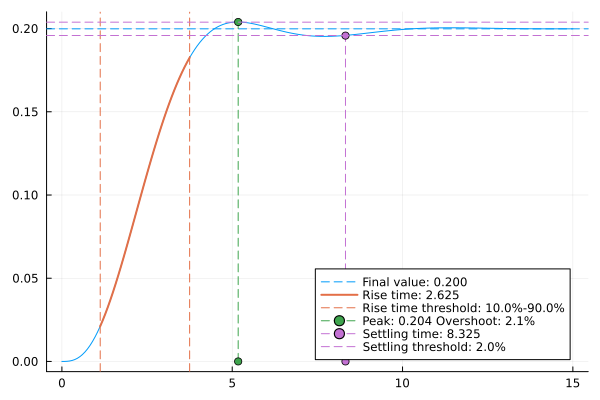

In [42]:
C1 = C[1, 1]   #  L/A  (prefiltro de la referencia)
C2 = -C[1, 2]   # -M/A  (realimentación de la salida)

G1 = feedback(G, C2)
T1 = minreal(C1*G1)           # de r a y  (debe ser igual a T)
print(T,T1)
referencia = 0.2   # rad
res = step(Gyr*referencia, 15)
plot(stepinfo(res))

Comparamos con la respuesta deseada $T(s)$: deben coincidir.

Observe que $u(t)$ tiende a cero, porque la planta tiene un integrador, pero lo hace muy lentamente. La razón es que $T(s)$ no contiene el cero de la planta en $s \approx -0.154$: `cont2dof` lo cancela con un polo de lazo cerrado en la misma posición. Ese polo no aparece en $\theta(t)$, pero sí en la señal de control:

### Ejercicios

- Use los polos diseñados por usted con la región de diseño en la actividad anterior

- Use la función ITAE, pero cambie $\omega_0$ (por ejemplo a 2 y a 3) y observe cómo cambian el tiempo de establecimiento de $\theta(t)$ y el valor máximo de la señal de control $\delta_e(t)$. 